In [1]:
import sys
sys.path += ["../scripts", "../scripts/old/p2_teach", "../scripts/p3_session"]
import contextlib
import functools
import io
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

import fit_surrender as fs
import human_data as hd
import session_experiment as se
import teach_experiment as te
import teach_experiment_rounds as ter
from session_analysis import OUT, measures

INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
PEOPLE, MODEL, ACCENT = "#8a8a85", "#2a78d6", "#e6550d"
LENGTHS = (6, 10, 13, 15)
AGENCIES = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
BINS = [(9, 11), (14, 16), (19, 21), (24, 26)]
AGENCY_COLORS = {0.0: "#93bfdc", 0.1: "#73a9d3", 0.3: "#5393c7", 0.5: "#3a7cb9", 0.7: "#2565a3", 0.9: "#154f88",
                 1.0: "#08306b"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def heat(ax, m, labels, rows, cols, lim, threshold):
    im = ax.imshow(m, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, labels[i][j], ha="center", va="center", fontsize=7.5,
                    color="white" if abs(m[i, j]) > threshold else INK)
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(rows)), rows)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(length=0, colors=MUTED)
    return im


@functools.lru_cache(None)
def loaded(run):
    return se.load_session(run, OUT)


def entry(run, spec):
    run_data = loaded(run)
    found = run_data["teachers"].get(se.teacher_name(spec))
    if not found or not found["sessions"] or not found["results"]:
        return None
    return {"config": run_data["config"], **found}


def score_at(e, s, n):
    return measures(e["results"][s][n], e["config"])[0]


def gains(e):
    return {s: score_at(e, s, min(by_n)) - score_at(e, s, max(by_n)) for s, by_n in e["results"].items()}


def ends(e):
    return {s: score_at(e, s, max(by_n)) for s, by_n in e["results"].items()}


def start_score(e):
    s, by_n = next(iter(e["results"].items()))
    return score_at(e, s, min(by_n))


SCORE_LABEL = "Held-out moves / optimal\n(unsolved = cap; lower is better)"
END_LABEL = "Held-out moves / optimal at the end\n(unsolved = cap; lower is better)"


def spend(e):
    records = [x for record in e["sessions"].values() for x in record]
    return sum(x["taught"] for x in records) / sum(x["moves"] for x in records)


def solved_as_played(e):
    return np.mean([x["solved"] for record in e["sessions"].values() for x in record])


def diff(g, h):
    d = np.array([g[s] - h[s] for s in g if s in h])
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), int((d < 0).sum()), len(d)


def mean_se(v):
    v = np.asarray([x for x in v if x == x], float)
    return v.mean(), v.std(ddof=1) / np.sqrt(len(v))


def session_curve(e):
    points = sorted({n for by_n in e["results"].values() for n in by_n})
    m, s = zip(*[mean_se(score_at(e, st, n) for st, by_n in e["results"].items() if n in by_n) for n in points])
    return np.array(points), np.array(m), np.array(s)


humans = hd.trials()

# Teaching with Rush Hour Project: Work until 11/16/26

## Introduction

Rush hour is a puzzle game under the category of "sliding block puzzles" in which the goal is to get a marked car (usually red) to the exit. Other cars block the way to the exit, and must be moved along the direction that they are facing to achieve this goal. A standard configuration is a 6x6 board in which cars occupy either two or three spaces, and the exit is in the middle right. 

![](Rush_Hour_solution_-_hardest_configuration.gif)

## Backwards And-Or Reasoning Model

To explore how teachers are able to help students in rush hour, first we have to develop a model of the student learner. As a model of human problem solving, Olieslagers et. al 2023 is ideal as it contains the implementation along with fitting to human data (both of which are publicly accessible). This paper proposes that humans reasons backwards from the goal state, framing the planning process as a tree search with two types of nodes.

- Or Node: Subgoals, or choosing between which cars to move. The root of the tree is always an Or Node (move the red car all the way to right).
- And Node: Actions, or choosing which way to move the car. If the action results in a collision with another car, an or node is created to handle that subgoal. Terminal ndoes are always and nodes.

Additionally, because humans are not perfect planners, they include a stopping probability parameter $\gamma$ which dictates the chance that at a given subgoal the human makes a random move. By fitting this parameter to human data, they were able to accurately predict what a person's next move might be.

The following graph shows the solve rate and moves / optimal for the data provided by the paper, separated by puzzle length. Although sovle rate does decrease over time due to human being allowed to play freely for the allotted time and give up, looking at only the first thirty trials it does seem possible that humans can learn to better solve puzzles over tiem.

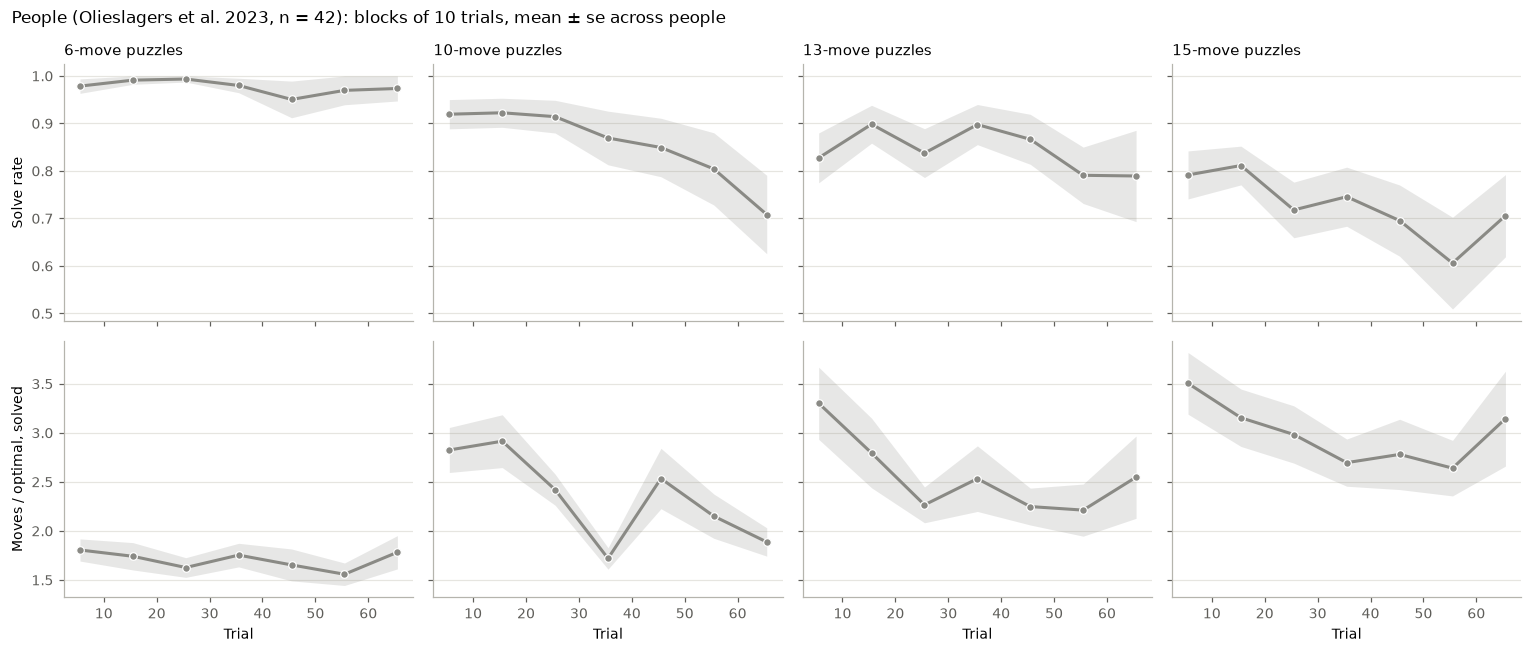

In [2]:
BLOCK = 10


def block_stats(df, who, block=BLOCK):
    df = df.assign(block=(df.trial - 1) // block)
    won = df[df.solved]
    ratio = (won.moves / won.distance).groupby([won[who], won.distance, won.block]).mean().rename("ratio")
    solve = df.groupby([who, "distance", "block"]).solved.mean().rename("solve")
    return pd.concat([ratio, solve], axis=1).reset_index()


def block_curve(rows, length, column, block=BLOCK):
    out = []
    for b, d in rows[rows.distance == length].groupby("block"):
        v = d[column].dropna()
        if len(v) >= 3:
            out.append((b * block + (block + 1) / 2, *mean_se(v)))
    return map(np.array, zip(*out))


people_rows = block_stats(humans, "subject")
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey="row")
for col, length in enumerate(LENGTHS):
    for row, (column, label) in enumerate((("solve", "Solve rate"), ("ratio", "Moves / optimal, solved"))):
        ax = axes[row, col]
        x, m, s = block_curve(people_rows, length, column)
        ax.fill_between(x, m - s, m + s, color=PEOPLE, alpha=0.2, lw=0)
        ax.plot(x, m, "-o", color=PEOPLE, lw=2, ms=5, mec="white", mew=0.8)
        if row == 0:
            ax.set_title(f"{length}-move puzzles")
        if col == 0:
            ax.set_ylabel(label)
        if row == 1:
            ax.set_xlabel("Trial")
        tidy(ax)
fig.suptitle(f"People (Olieslagers et al. 2023, n = {humans.subject.nunique()}): blocks of {BLOCK} trials, mean ± se "
             "across people", x=0.01, ha="left")
plt.tight_layout()
plt.show()

# trend_rows = []
# for part, d in (("trials 1-30", humans[humans.trial <= 30]), ("trials 31+", humans[humans.trial > 30])):
#     won = d[d.solved].assign(log_ratio=lambda x: np.log(x.moves / x.distance))
#     trend_rows.append({"trials": part,
#                        "log moves / optimal per 10 trials": "{:+.3f} ± {:.3f}".format(*hd.trend(won, "log_ratio")),
#                        "solve rate per 10 trials": "{:+.3f} ± {:.3f}".format(
#                            *hd.trend(d.assign(s=d.solved.astype(float)), "s"))})
# display(pd.DataFrame(trend_rows).set_index("trials"))

Although an accurate predictor of a person's next move, the original model was never meant to solve an entire puzzle on its own. Therfore, instead of playing a single and then restarting the planning process every move, reaching a terminal node now allows the whole plan to get played out. As the following graph shows, this makes an and-or much more efficient at solving puzzles, even at the same gamma. Although a good model of how a human solves a single puzzle, there is no notion of learning to get better at solving puzzles over time or otherwise gaining some advantage from a teacher.

In [3]:
AO = "../models/summary/and_or_humans"
GAMMA = 0.07
moves = np.load(os.path.join(AO, "moves.npz"))
GAMMAS, LOGP, SUBJ, TRIAL = moves["gammas"], moves["logp"], moves["subject"], moves["trial"]
sims = pd.read_csv(os.path.join(AO, "simulations.csv"))
paper = pd.read_csv("../23vrb-osfstorage-archive/data/processed_data/df_models.csv")
paper["param"] = paper.params.str.strip("[]").str.split(",").str[0].astype(float)


def mle(ll):
    i = int(np.clip(ll.argmax(), 1, len(ll) - 2))
    x = np.log(GAMMAS[i - 1:i + 2])
    a, b, c = np.polyfit(x, ll[i - 1:i + 2], 2)
    peak = -b / (2 * a) if a < 0 else x[1]
    return float(np.exp(peak)), float(-(np.polyval([a, b, c], peak)))


fits = pd.DataFrame([(s, *mle(LOGP[SUBJ == s].sum(0)), int((SUBJ == s).sum())) for s in np.unique(SUBJ)],
                    columns=["subject", "gamma", "nll", "moves"]).set_index("subject")
pg = paper[paper.model == "gamma_only_model"].set_index("subject")
fits["paper gamma"], fits["paper nll"] = pg.param, pg.nll
display(pd.DataFrame({"this repo's port": [fits.gamma.median(), fits.gamma.mean(), mle(LOGP.sum(0))[0],
                                           fits.nll.sum(), len(fits), int(fits.moves.sum())],
                      "paper": [fits["paper gamma"].median(), fits["paper gamma"].mean(), np.nan,
                                fits["paper nll"].sum(), pg.param.notna().sum(), np.nan]},
                     index=["median γ per person", "mean γ per person", "one γ for everyone", "total NLL", "people",
                            "moves"]).round(3))

,this repo's port,paper
median γ per person,0.067,0.069
mean γ per person,0.068,0.069
one γ for everyone,0.068,NaN
total NLL,94565.144,90878.860
people,42.000,42.000
moves,51285.000,NaN


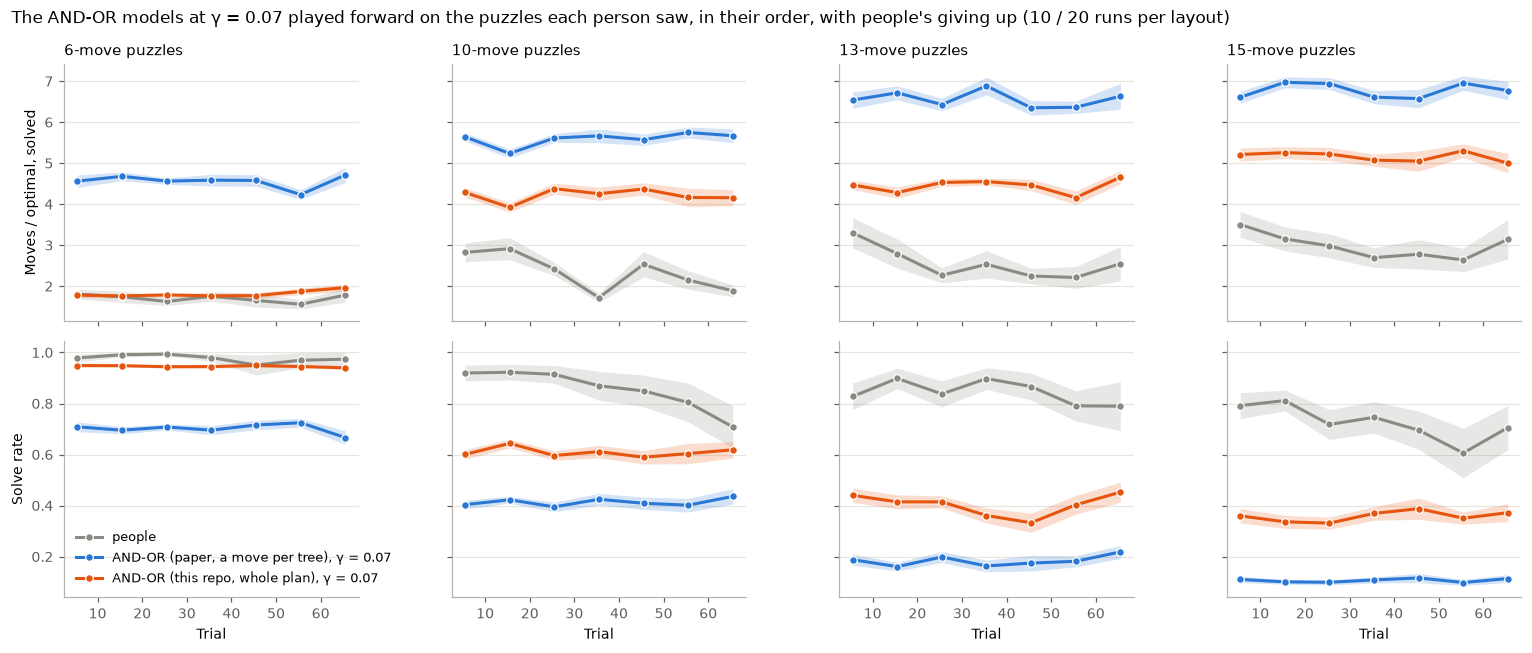

In [4]:
EDGES, RATES, _ = hd.surrender_hazard()


def expected(group):
    d = group.distance.iloc[0]
    w = np.array([fs.survival(int(m), d, EDGES, RATES, 1.0) if s else 0.0 for m, s in zip(group.moves, group.solved)])
    ratio = (w * group.moves / d).sum() / w.sum() if w.sum() else np.nan
    return pd.Series({"solve": w.mean(), "ratio": ratio})


by_puzzle = sims[np.isclose(sims.gamma, GAMMA)].groupby("instance").apply(expected, include_groups=False)


def model_rows(by_puzzle):
    """A model's expected result on each human trial's layout, averaged like people's (person, length, block)."""
    pred = humans.join(by_puzzle.add_prefix("p_"), on="instance")
    return pred.assign(block=(pred.trial - 1) // BLOCK).groupby(["subject", "distance", "block"])[
        ["p_ratio", "p_solve"]].mean().rename(columns={"p_ratio": "ratio", "p_solve": "solve"}).reset_index()


pred_rows = model_rows(by_puzzle)
# This repo's solver (and_or.solve): the whole plan is played out instead of one move per tree; protect_movers off,
# as for the apprentice's expert. 20 runs per layout from scripts/p3_session/and_or_gamma.py, same cap.
REPO_SWEEP = pd.read_csv("../models/sessions/and_or_gamma/sweep.csv")
repo_rows = model_rows(REPO_SWEEP[~REPO_SWEEP.protect & np.isclose(REPO_SWEEP.gamma, GAMMA)]
                       .groupby("instance").apply(expected, include_groups=False))

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey="row")
for col, length in enumerate(LENGTHS):
    for row, (column, label) in enumerate((("ratio", "Moves / optimal, solved"), ("solve", "Solve rate"))):
        ax = axes[row, col]
        for rows, name, color in ((people_rows, "people", PEOPLE),
                                  (pred_rows, f"AND-OR (paper, a move per tree), γ = {GAMMA:g}", MODEL),
                                  (repo_rows, f"AND-OR (this repo, whole plan), γ = {GAMMA:g}", ACCENT)):
            x, m, s = block_curve(rows, length, column)
            ax.fill_between(x, m - s, m + s, color=color, alpha=0.2, lw=0)
            ax.plot(x, m, "-o", color=color, lw=2, ms=5, mec="white", mew=0.8, label=name)
        if row == 0:
            ax.set_title(f"{length}-move puzzles")
        if col == 0:
            ax.set_ylabel(label)
        if row == 1:
            ax.set_xlabel("Trial")
        tidy(ax)
axes[1, 0].legend(loc="lower left")
fig.suptitle(f"The AND-OR models at γ = {GAMMA:g} played forward on the puzzles each person saw, in their order, "
             "with people's giving up (10 / 20 runs per layout)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

C:\Users\yijos\AppData\Local\Temp\ipykernel_2752\61412542.py:108: RuntimeWarning: Mean of empty slice
  return v.mean(), v.std(ddof=1) / np.sqrt(len(v))
C:\dev\GitHub\rush-hour\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\dev\GitHub\rush-hour\.venv\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\dev\GitHub\rush-hour\.venv\Lib\site-packages\numpy\_core\_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\dev\GitHub\rush-hour\.venv\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


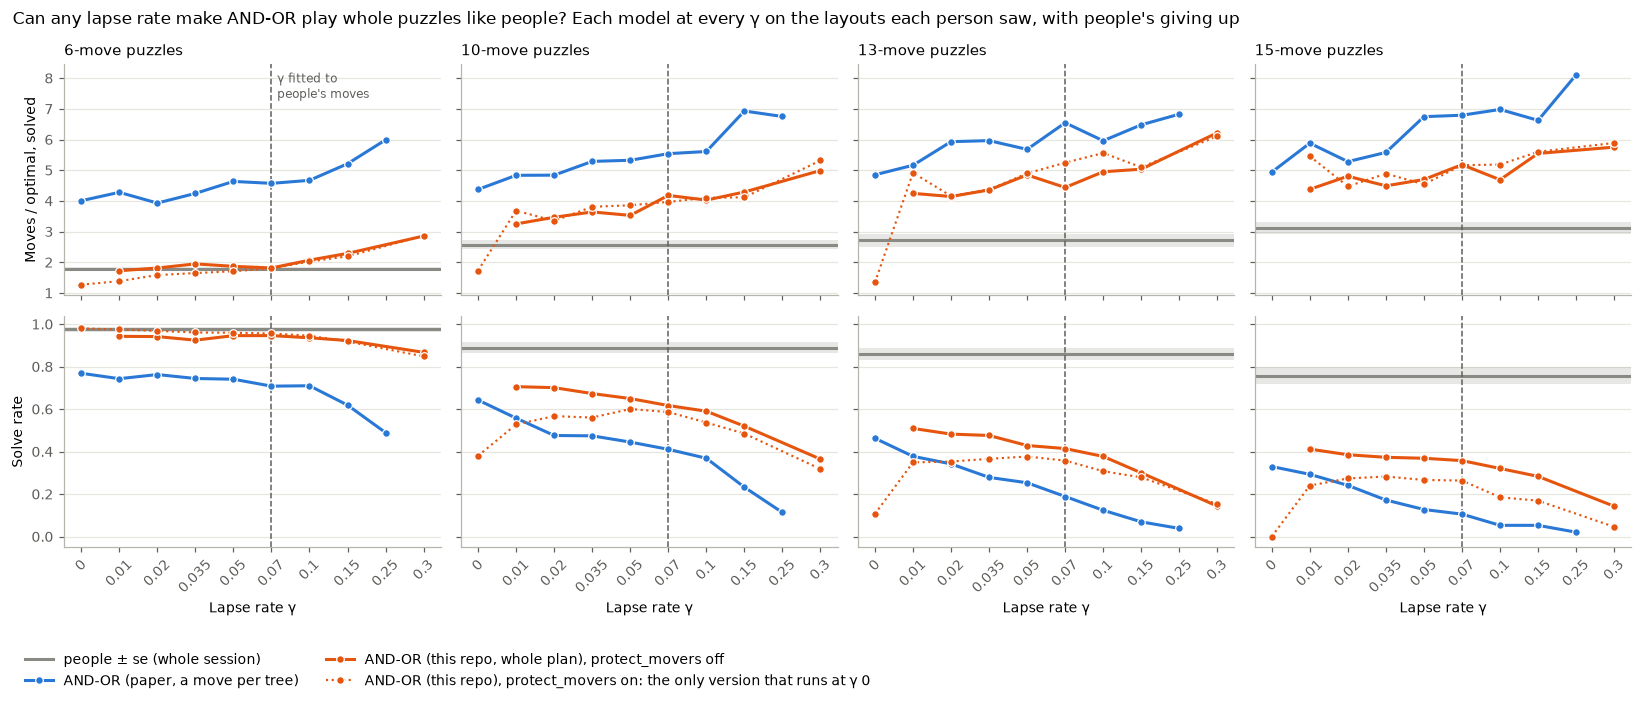

In [5]:
# Both AND-OR models over the lapse rate γ, against people: every human trial predicted by its layout's runs, with
# people's giving up (expected, above), averaged per person and then across people, as people are.
SWEEP_GAMMAS = sorted(set(sims.gamma.round(4)) | set(REPO_SWEEP.gamma.round(4)))
SWEEP_MODELS = (("AND-OR (paper, a move per tree)", sims, MODEL, "-"),
                ("AND-OR (this repo, whole plan), protect_movers off", REPO_SWEEP[~REPO_SWEEP.protect], ACCENT, "-"),
                ("AND-OR (this repo), protect_movers on: the only version that runs at γ 0",
                 REPO_SWEEP[REPO_SWEEP.protect], ACCENT, ":"))


def per_person(rows, column, length):
    "Mean ± se across people of each person's mean, on the trials of one length."
    v = rows[rows.distance == length].groupby("subject")[column].mean().dropna()
    return mean_se(v)


people_won = humans.assign(ratio=np.where(humans.solved, humans.moves / humans.distance, np.nan),
                           solve=humans.solved.astype(float))
sweep_pts = []
for name, runs, *_ in SWEEP_MODELS:
    for gamma, g in runs.groupby(runs.gamma.round(4)):
        pred = humans.join(g.groupby("instance").apply(expected, include_groups=False), on="instance")
        for length in LENGTHS:
            sweep_pts.append({"model": name, "gamma": gamma, "distance": length,
                              "ratio": per_person(pred, "ratio", length)[0],
                              "solve": per_person(pred, "solve", length)[0]})
sweep_pts = pd.DataFrame(sweep_pts)
xpos = {g: i for i, g in enumerate(SWEEP_GAMMAS)}

fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharex=True, sharey="row")
for col, length in enumerate(LENGTHS):
    for row, (column, label) in enumerate((("ratio", "Moves / optimal, solved"), ("solve", "Solve rate"))):
        ax = axes[row, col]
        m, s = per_person(people_won, column, length)
        ax.axhspan(m - s, m + s, color=PEOPLE, alpha=0.2, lw=0)
        ax.axhline(m, color=PEOPLE, lw=2, label="people ± se (whole session)")
        ax.axvline(xpos[GAMMA], color=MUTED, lw=1, ls="--")
        for name, _, color, ls in SWEEP_MODELS:
            g = sweep_pts[(sweep_pts.model == name) & (sweep_pts.distance == length)].sort_values("gamma")
            ax.plot(g.gamma.map(xpos), g[column], ls + "o", color=color, lw=2 if ls == "-" else 1.4, ms=5,
                    mec="white", mew=0.8, label=name)
        if row == 0:
            ax.set_title(f"{length}-move puzzles", loc="left")
        if col == 0:
            ax.set_ylabel(label)
        if row == 1:
            ax.set_xticks(range(len(SWEEP_GAMMAS)), [f"{x:g}" for x in SWEEP_GAMMAS], rotation=45)
            ax.set_xlabel("Lapse rate γ")
        tidy(ax)
axes[0, 0].text(xpos[GAMMA] + 0.15, 0.97, "γ fitted to\npeople's moves", transform=axes[0, 0].get_xaxis_transform(),
                va="top", fontsize=8, color=MUTED)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower left", ncol=2, bbox_to_anchor=(0.01, 0), fontsize=9)
fig.suptitle("Can any lapse rate make AND-OR play whole puzzles like people? Each model at every γ on the layouts "
             "each person saw, with people's giving up", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()


## Expert Iteration

Reinforcement learning algorithms such as DQN and REINFORCE are able to learn from experience just as a human would, but they would struggle with the sparse rewards of Rush Hour and a lack of planning process does that seem very similar to how a human would actually think. To get the best of both worlds, Expert Iteration from Anthony et. al 2017 is used as a combination of an "expert" tree search and and an "apprentice" network. In each round, first the and-or reasoning model creates a number of attempts for different puzzles, with the gamma parameter that we fitted earlier. Next, the successful solutions are turned into labels for the apprentice network to generalize. Finally, the apprentice network helps order the subgoals for the and-or reasoning model, and the process repeats for every round that there is.

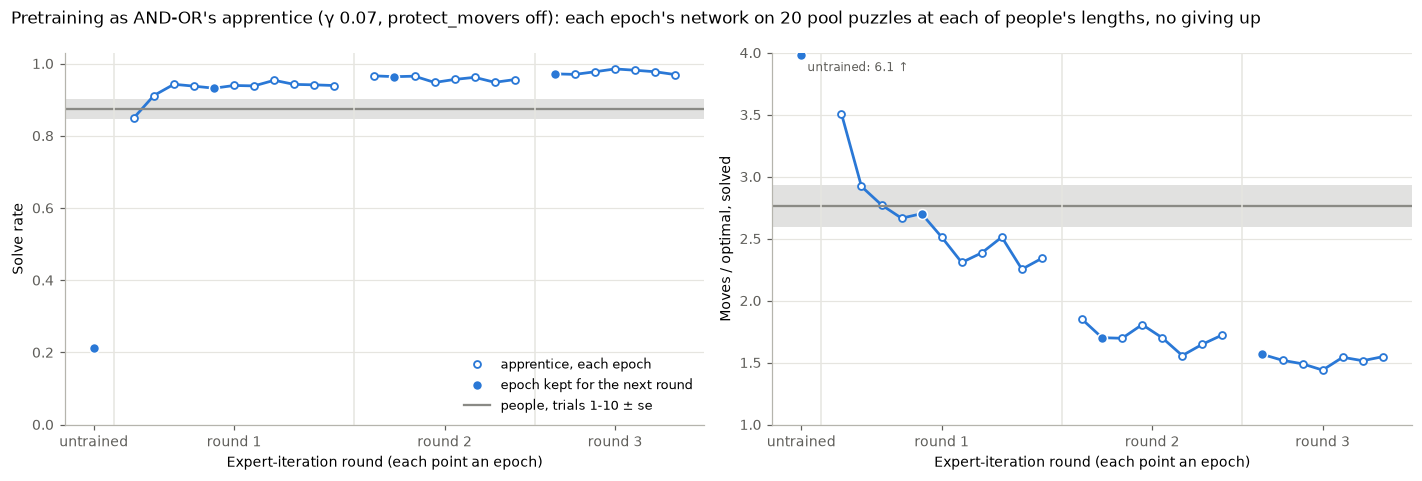

In [6]:
APP_CURVE = "../models/summary/apprentice_curve"  # written by scripts/summary/apprentice_curve.py
APPRENTICE = ("unprotected", "../models/apprentice/gamma0.07_free")  # γ 0.07, protect_movers off: (cache key, folder)
RATIO_TOP = 4.0  # the untrained network's moves / optimal is drawn at the top edge, its value printed
(hs, hs_se), (hr, hr_se), first10 = fs.human_target(BLOCK)
app_puzzles = fs.puzzle_set("test")
app_edges, app_rates, _ = hd.surrender_hazard()
manifest = json.load(open(os.path.join(APPRENTICE[1], "manifest.json")))
epochs = {}  # round: epochs saved in it
for m in manifest:
    epochs[m["round"]] = max(epochs.get(m["round"], 0), m["epoch"])
start_of = {r: sum(max(1, epochs[q]) + 1 for q in epochs if q < r) for r in epochs}  # a gap between rounds

pts = []
for m in manifest:
    runs = json.load(open(os.path.join(APP_CURVE, f"{APPRENTICE[0]}_{m['file'][:-3]}.json")))
    pts.append((start_of[m["round"]] + max(m["epoch"] - 1, 0),
                *fs.predict(runs, app_puzzles, first10, app_edges, app_rates, 0.0, True), m["kept"]))
x, solve, ratio, kept = map(np.array, zip(*pts))
ratios_untrained = list(ratio[:1])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, y in ((a1, solve), (a2, ratio)):
    for r in epochs:  # one line per round: a round starts from the previous round's kept epoch
        idx = [i for i, m in enumerate(manifest) if m["round"] == r]
        ax.plot(x[idx], y[idx], "-", color=MODEL, lw=1.8)
    ax.plot(x[~kept], y[~kept], "o", color=MODEL, ms=4.5, mfc="white", mew=1.2, label="apprentice, each epoch")
    ax.plot(x[kept], y[kept], "o", color=MODEL, ms=6.5, mec="white", label="epoch kept for the next round")
for ax, h, hse in ((a1, hs, hs_se), (a2, hr, hr_se)):
    ax.axhspan(h - hse, h + hse, color=PEOPLE, alpha=0.25, lw=0)
    ax.axhline(h, color=PEOPLE, lw=1.5, label="people, trials 1-10 ± se")
    for r in epochs:
        if r > 0:
            ax.axvline(start_of[r] - 1, color=GRID, lw=1)
    ax.set_xticks([start_of[r] + (max(1, epochs[r]) - 1) / 2 for r in epochs],
                  ["untrained"] + [f"round {r}" for r in epochs if r > 0])
    ax.set_xlabel("Expert-iteration round (each point an epoch)")
    tidy(ax)
a1.set_ylabel("Solve rate")
a1.set_ylim(0, 1.03)
a1.legend(loc="lower right")
a2.set_ylabel("Moves / optimal, solved")
untrained = [p for p in ratios_untrained if p > RATIO_TOP]
if untrained:
    a2.annotate(f"untrained: {max(untrained):.1f} ↑", (0, RATIO_TOP), xytext=(4, -12), textcoords="offset points",
                fontsize=8, color=MUTED)
a2.set_ylim(1, RATIO_TOP)
for line in a2.lines:  # pin points above the top to the edge
    y = np.asarray(line.get_ydata(), float)
    line.set_ydata(np.minimum(y, RATIO_TOP - 0.02))
fig.suptitle("Pretraining as AND-OR's apprentice (γ 0.07, protect_movers off): each epoch's network on 20 pool "
             "puzzles at each of people's lengths, no giving up", x=0.01, ha="left")
plt.tight_layout()
plt.show()


Ideally the perfomrance of this network will be fit to human performance, but a limitation of the above model is that it takes much more data for a network to learn from puzzles as a human does. This issue can be mitigated in two ways:

- pretraining the network to a human comparable performance
- showing multiple puzzles for every one puzzle a human sees

For the first one, it appears that the best starting performance for the network is actually midway through round 1, meaning that the full ExIt cycle is not needed (this makes it more like imitation learning of the And-Or tree search). On the other hand, the "multiplier" can be swept to best match human learning rate, along with another parameter called hindsight. This allows the model to learn from its own solve attempts by finding "shortcuts" in an otherwise inefficient path, ranging from none ("own") to windows of certain lengths (up to "full").

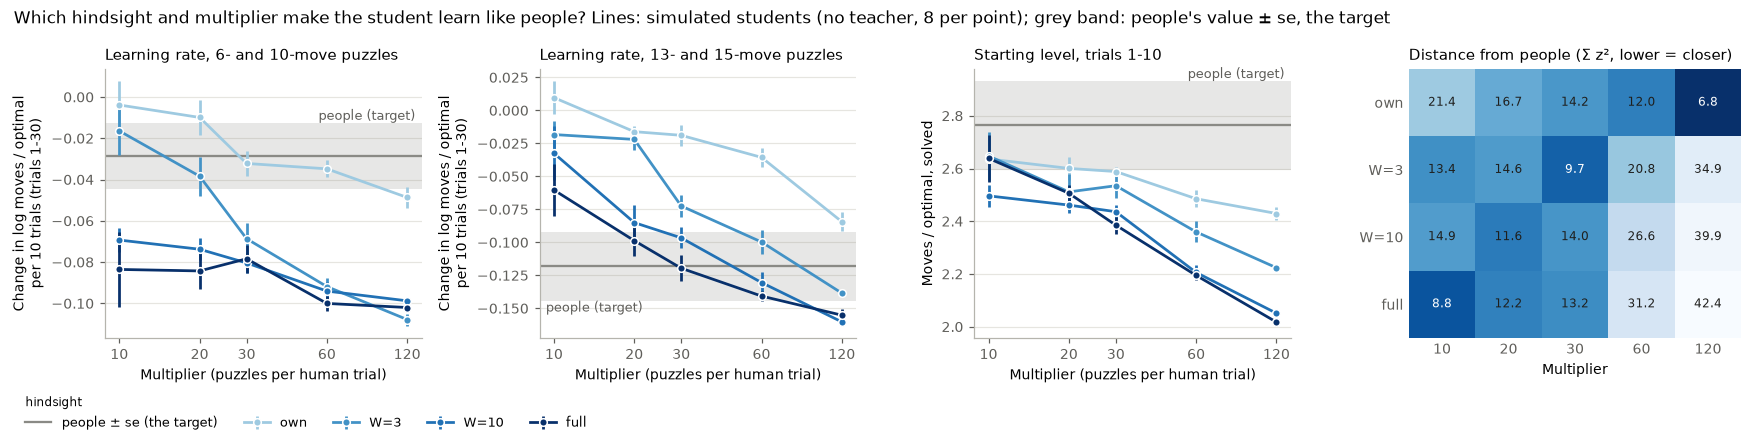

In [7]:
SPLIT = 30
WINDOWS = {"own": "own", "W=3": "w3", "W=10": "w10", "full": "all"}
WINDOW_COLORS = {"own": "#9ecae1", "W=3": "#4292c6", "W=10": "#2171b5", "full": "#08306b"}
MULTIPLIERS = [10, 20, 30, 60, 120]
STATS = {"short": "Learning rate, 6- and 10-move puzzles", "long": "Learning rate, 13- and 15-move puzzles",
         "start": "Starting level, trials 1-10"}
STAT_YLABEL = {"short": "Change in log moves / optimal\nper 10 trials (trials 1-30)",
               "long": "Change in log moves / optimal\nper 10 trials (trials 1-30)",
               "start": "Moves / optimal, solved"}
PEOPLE_LABEL_AT = {"short": ("right", "above"), "long": ("left", "below"), "start": ("right", "above")}  # clear of the lines


def played(window, m):
    run = f"people_{WINDOWS[window]}" + ("" if m == 30 else f"_m{m}")
    e = entry(run, "none")
    return pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec])


def stats(df, person, puzzle):
    early = df[(df.trial <= SPLIT) & df.solved].assign(log_ratio=lambda d: np.log(d.moves / d.distance))
    out = {name: hd.trend(early[early.distance.isin(ds)], "log_ratio", person=person, puzzle=puzzle)
           for name, ds in (("short", (6, 10)), ("long", (13, 15)))}
    first = df[(df.trial <= BLOCK) & df.solved]
    out["start"] = mean_se((first.moves / first.distance).groupby(first[person]).mean())
    return out


people_stats = stats(humans, "subject", "instance")
rows = []
for w in WINDOWS:
    for m in MULTIPLIERS:
        st = stats(played(w, m), "student", "puzzle")
        row = {"window": w, "multiplier": m}
        for k in STATS:
            row[k], row[k + " se"] = st[k]
            row["z " + k] = (st[k][0] - people_stats[k][0]) / np.hypot(st[k][1], people_stats[k][1])
        row["misfit"] = sum(row["z " + k] ** 2 for k in STATS)
        rows.append(row)
rate_grid = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1, 1, 1.05]})
for ax, (k, title) in zip(axes, STATS.items()):
    hb, hse = people_stats[k]
    ax.axhspan(hb - hse, hb + hse, color=PEOPLE, alpha=0.2, lw=0)
    ax.axhline(hb, color=PEOPLE, lw=1.5, label="people ± se (the target)")
    side, where = PEOPLE_LABEL_AT[k]
    ax.text(0.98 if side == "right" else 0.02, hb + hse if where == "above" else hb - hse, "people (target)",
            transform=ax.get_yaxis_transform(), ha=side, va="bottom" if where == "above" else "top", fontsize=8.5,
            color=MUTED)
    for w in WINDOWS:
        g = rate_grid[rate_grid.window == w]
        ax.errorbar(g.multiplier, g[k], yerr=g[k + " se"], fmt="-o", color=WINDOW_COLORS[w], lw=1.8, ms=5,
                    mec="white", label=w)
    ax.set_xscale("log")
    ax.set_xticks(MULTIPLIERS, [str(m) for m in MULTIPLIERS])
    ax.minorticks_off()
    ax.set_xlabel("Multiplier (puzzles per human trial)")
    ax.set_title(title)
    ax.set_ylabel(STAT_YLABEL[k])
    tidy(ax)
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower left", ncol=len(labels), bbox_to_anchor=(0.01, 0), title="hindsight",
           title_fontsize=8, alignment="left")
mm = rate_grid.pivot(index="window", columns="multiplier", values="misfit").loc[list(WINDOWS)]
im = axes[3].imshow(np.log10(mm.values), cmap="Blues_r", aspect="auto")
for i in range(mm.shape[0]):
    for j in range(mm.shape[1]):
        axes[3].text(j, i, f"{mm.values[i, j]:.1f}", ha="center", va="center", fontsize=8,
                     color="white" if mm.values[i, j] < 10 else INK)
axes[3].set_xticks(range(len(MULTIPLIERS)), MULTIPLIERS)
axes[3].set_yticks(range(len(WINDOWS)), list(WINDOWS))
axes[3].set_xlabel("Multiplier")
axes[3].set_title("Distance from people (Σ z², lower = closer)")
for side in axes[3].spines.values():
    side.set_visible(False)
axes[3].tick_params(length=0, colors=MUTED)
fig.suptitle("Which hindsight and multiplier make the student learn like people? Lines: simulated students (no "
             "teacher, 8 per point); grey band: people's value ± se, the target", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

With these improvements, the model now matches the learning curve of humans much more closely, with the exception of solve rate due to the aforementioned confounds of people giving up early. Importantly, they are only fit to the first thirty trials of human data (beyond which many participants drop out or give up much more easily, hence the lower solve rate).

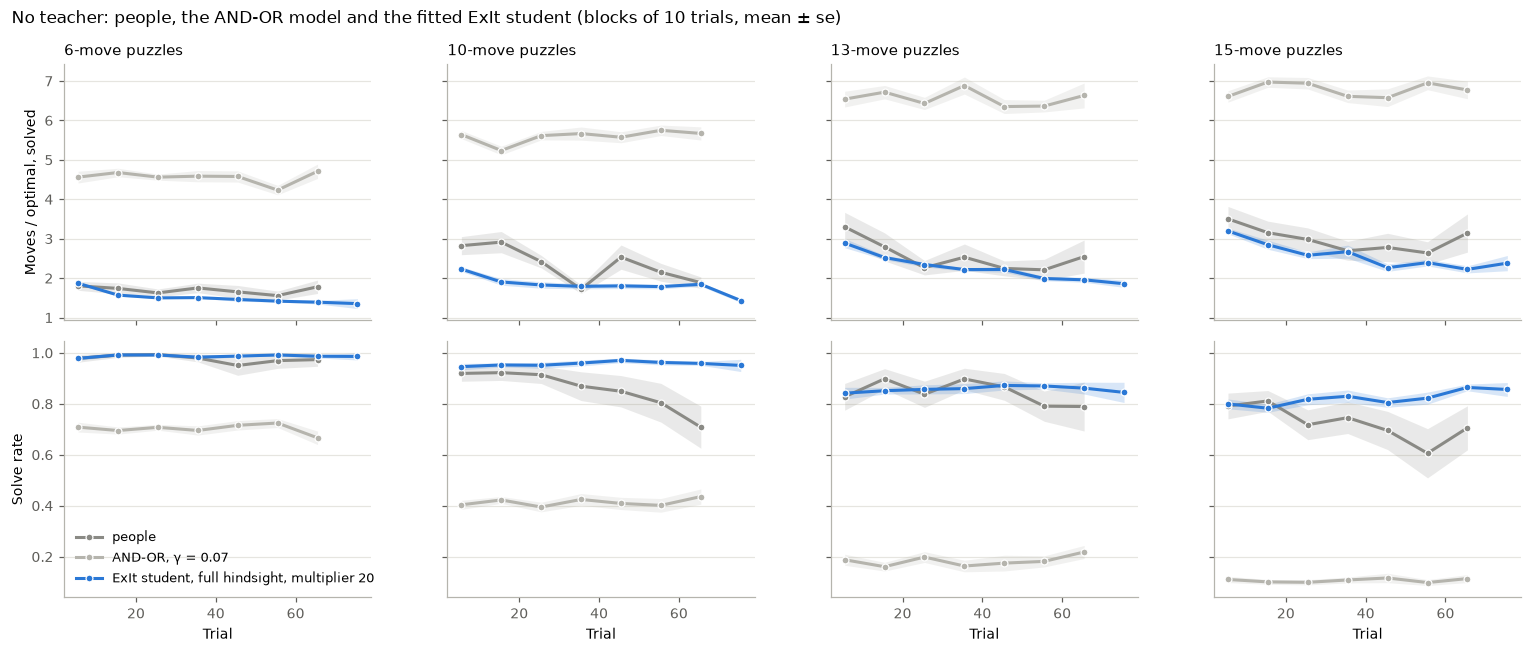

In [8]:
e = entry("people_all_m20", "none")
student_rows = block_stats(pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec]),
                           "student")
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey="row")
for col, length in enumerate(LENGTHS):
    for row, (column, label) in enumerate((("ratio", "Moves / optimal, solved"), ("solve", "Solve rate"))):
        ax = axes[row, col]
        for rows, name, color in ((people_rows, "people", PEOPLE), (pred_rows, f"AND-OR, γ = {GAMMA:g}", RULE),
                                  (student_rows, "ExIt student, full hindsight, multiplier 20", MODEL)):
            x, m, s = block_curve(rows, length, column)
            ax.fill_between(x, m - s, m + s, color=color, alpha=0.18, lw=0)
            ax.plot(x, m, "-o", color=color, lw=2, ms=4.5, mec="white", mew=0.8, label=name)
        if row == 0:
            ax.set_title(f"{length}-move puzzles")
        if col == 0:
            ax.set_ylabel(label)
        if row == 1:
            ax.set_xlabel("Trial")
        tidy(ax)
axes[1, 0].legend(loc="lower left")
fig.suptitle(f"No teacher: people, the AND-OR model and the fitted ExIt student (blocks of {BLOCK} trials, mean ± se)",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

## Teacher Models

Now that a pretrained network is chosen and the learning rate is calibrated, the next step is to create a teaching agent that assist the student agent in solving these puzzles. There are a few ways to control the type of help that a student receives:

- Frequency: Rush hour can be broken up into discrete moves, so at each step the teacher has to decide whether to help or not. More assistance means more moves helped and vice versa for less assistance.
- Timing: Teachers can help uniformly across the course of a solve attempt (as in the random teacher below) or it could attempt to help only when most useful, perhaps with heuristics (correct after mistake) or an internal model of the student (bayesian).
- Quality: The simplest way to assist a student at a given time step is to show them the right move by making it for them. There could also be less strong forms of assistance, such as selecting the car that should be moved (but not which direction) or simply pointing out the mistakes a student makes (flag mistakes).

During a session, the same pretrained network is tasked with solving puzzles either without assistance or with one of the forms of assistance mentioned above. Afterwards, their unassisted performance on held-out puzzles is measured as moves over optimal, or how efficiently they could get to the goal. As can be seen below, flag mistakes and correct after mistakes does not appear to do better than random, while bayesian appears to match or slightly exceed. Keep in mind that further refinements to the bayesian teacher were made which allowed it to exceed performance later in this notebook.

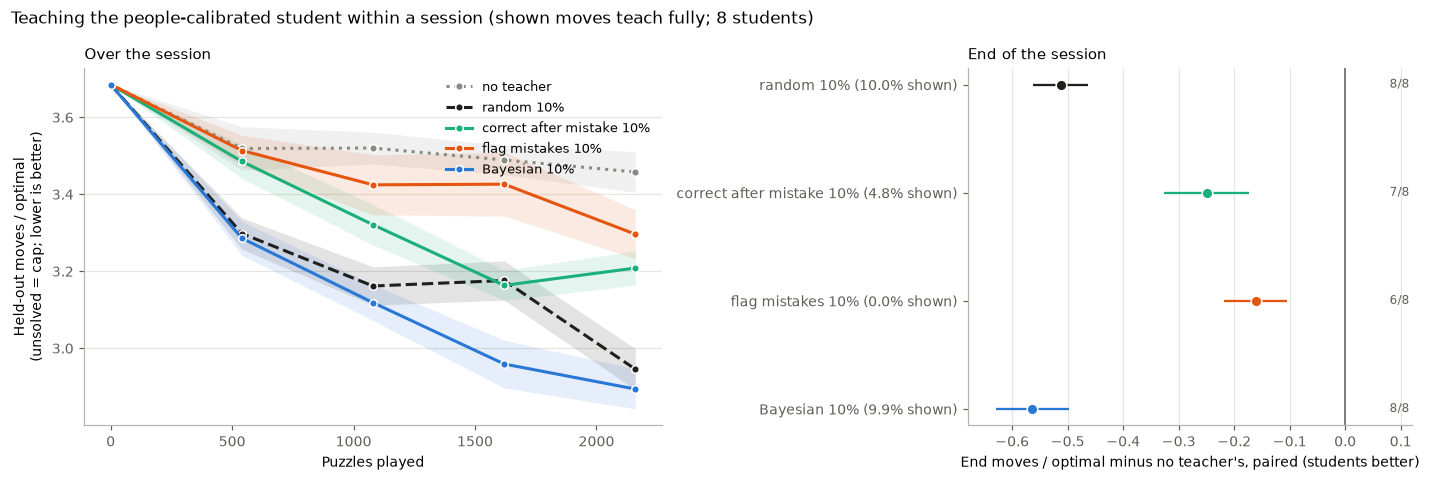

In [9]:
SESSION_TEACHERS = {"none": ("no teacher", PEOPLE, ":"), "random:0.1": ("random 10%", INK, "--"),
                    "correct-after:0.1": ("correct after mistake 10%", "#1baf7a", "-"),
                    "flag:0.1": ("flag mistakes 10%", ACCENT, "-"), "bayes:0.1": ("Bayesian 10%", MODEL, "-")}
base = entry("fitted_teachers", "none")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
rows = []
for spec, (name, color, ls) in SESSION_TEACHERS.items():
    e = entry("fitted_teachers", spec)
    x, m, s = session_curve(e)
    a1.fill_between(x, m - s, m + s, color=color, alpha=0.12, lw=0)
    a1.plot(x, m, ls + "o", color=color, lw=2, ms=5, mec="white", label=name)
    if spec != "none":
        d, se_, better, n = diff(ends(e), ends(base))
        rows.append((name, d, se_, better, n, spend(e)))
a1.set_xlabel("Puzzles played")
a1.set_ylabel(SCORE_LABEL)
a1.legend(loc="upper right")
a1.set_title("Over the session")
tidy(a1)
y = np.arange(len(rows))[::-1]
xlo, xhi = min(min(r[1] - r[2] for r in rows), 0) - 0.05, max(max(r[1] + r[2] for r in rows), 0) + 0.12
for yy, (name, d, s, better, n, sh) in zip(y, rows):
    a2.errorbar(d, yy, xerr=s, fmt="o", color=SESSION_TEACHERS[[k for k, v in SESSION_TEACHERS.items()
                                                                  if v[0] == name][0]][1], ms=7, mec="white")
    a2.text(xhi - 0.04, yy, f"{better}/{n}", va="center", fontsize=8, color=MUTED)
a2.axvline(0, color=MUTED, lw=1)
a2.set_yticks(y, [f"{r[0]} ({r[5]:.1%} shown)" for r in rows])
a2.set_xlim(xlo, xhi)
a2.set_xlabel("End moves / optimal minus no teacher's, paired (students better)")
a2.set_title("End of the session")
tidy(a2, grid="x")
fig.suptitle("Teaching the people-calibrated student within a session (shown moves teach fully; 8 students)",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

## $\Delta$ Agency

One problem with the previous teaching setup is that more help seems to be always better than less help, which would go against the assistance dilemma phenomenon which was the inspiration for this project. Although experiments were done to see if this effect could be reproduced as a consequence of the current student agent (for example, that more exploration due to less assistance could result in better learning), it seemed like the benefit of high quality labels from an oracle teacher was too strong. In humans, working through a problem on one's own usually serves to be better remembered and learned that simply watching a demonstration of the solution, as is done here. Therefore, a parameter $\Delta A$ (agency) was made to capture this phenomenon. It could represent curiosity, motivation, or attention, but the idea is that students learn less when simply shown a move, so a $\Delta A$ proportion of the learning steps for the network are skipped.

Even when $\Delta A$ is set to 0, some amount of teaching does still have a positive effect due to the fact that more puzzles are solved and therefore more of a student's own moves can be learned from (students do not learn from unsolved attempts). However, as shown below setting this parameter to a low value like 0.1 is able to reproduce the assistance dilemma using a random help teacher; around 10% help is optimal while more or less results in decreased performance.

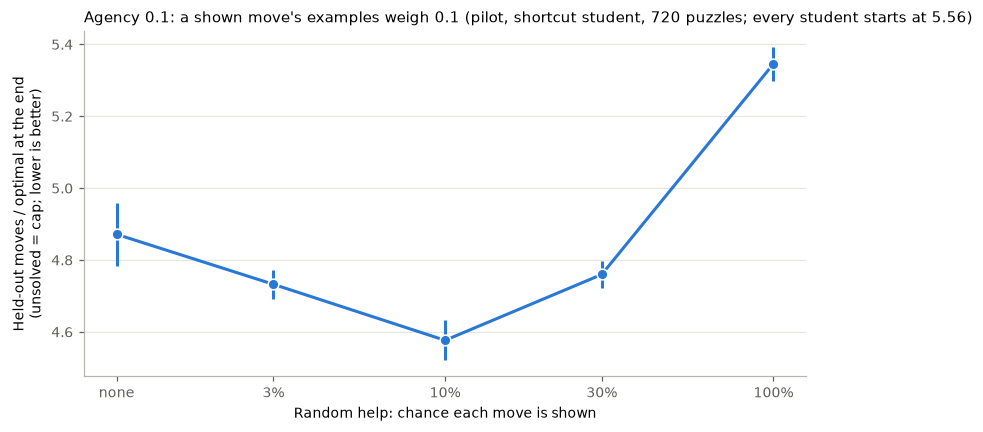

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
pts = []
for spec in ("none", "random:0.03", "random:0.1", "random:0.3", "random:1.0"):
    e = entry("pilot_all_agency0.1_skip", spec)
    pts.append((0.01 if spec == "none" else float(spec.split(":")[1]), *mean_se(ends(e).values())))
x, m, s = map(np.array, zip(*pts))
ax.errorbar(x, m, yerr=s, fmt="-o", color=MODEL, lw=2, ms=7, mec="white")
ax.set_xscale("log")
ax.set_xticks(x, ["none", "3%", "10%", "30%", "100%"])
ax.minorticks_off()
ax.set_xlabel("Random help: chance each move is shown")
ax.set_ylabel(END_LABEL)
ax.set_title(f"Agency 0.1: a shown move's examples weigh 0.1 (pilot, shortcut student, 720 puzzles; every "
             f"student starts at {start_score(e):.2f})")
tidy(ax)
plt.tight_layout()
plt.show()

Importantly, $\Delta A$ does not appear to greatly affect the the performance of the student within a session (as shown by the similarity of the help curves on the right graph) but it does appear to affect the degree to which more help is *detrimental* to a student. For example, 30% help is better than baseline with a $Delta A$ set to 0.3, but not when it is set to 0.

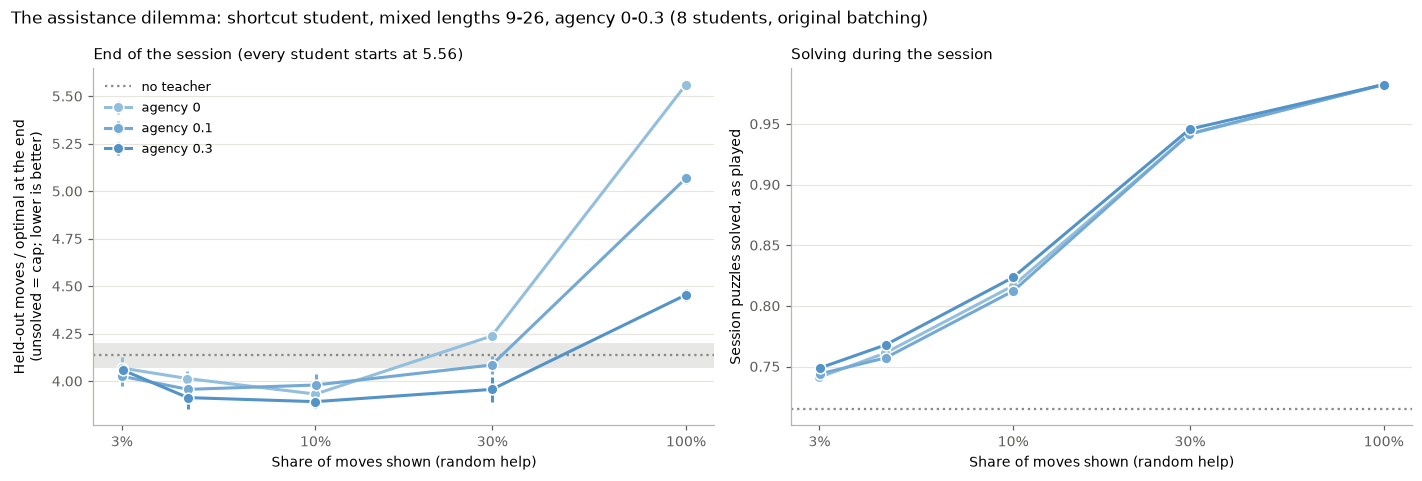

In [11]:
OLD_RUNS = {0.0: "teach_shortcut_agency0", 0.1: "teach_shortcut_agency0.1", 0.3: "teach_shortcut_agency0.3"}
none = entry("teach_shortcut_agency0.3", "none")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
nm, ns = mean_se(ends(none).values())
for a, run in OLD_RUNS.items():
    pts = sorted((spend(e), solved_as_played(e), *mean_se(ends(e).values()))
                 for spec in ("random:0.03", "random:0.045", "random:0.1", "random:0.3", "random:1.0")
                 for e in [entry(run, spec)] if e is not None)
    x, sp, m, s = map(np.array, zip(*pts))
    a1.errorbar(x, m, yerr=s, fmt="-o", color=AGENCY_COLORS[a], lw=2, ms=7, mec="white", label=f"agency {a:g}")
    a2.plot(x, sp, "-o", color=AGENCY_COLORS[a], lw=2, ms=7, mec="white", label=f"agency {a:g}")
a1.axhspan(nm - ns, nm + ns, color=PEOPLE, alpha=0.2, lw=0)
a1.axhline(nm, color=PEOPLE, lw=1.5, ls=":", label="no teacher")
a2.axhline(solved_as_played(none), color=PEOPLE, lw=1.5, ls=":", label="no teacher")
for ax in (a1, a2):
    ax.set_xscale("log")
    ax.set_xticks([0.03, 0.1, 0.3, 1], ["3%", "10%", "30%", "100%"])
    ax.minorticks_off()
    ax.set_xlabel("Share of moves shown (random help)")
    tidy(ax)
a1.set_ylabel(END_LABEL)
a1.legend(loc="upper left")
a1.set_title(f"End of the session (every student starts at {start_score(none):.2f})")
a2.set_ylabel("Session puzzles solved, as played")
a2.set_title("Solving during the session")
fig.suptitle("The assistance dilemma: shortcut student, mixed lengths 9-26, agency 0-0.3 (8 students, original "
             "batching)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## Bayesian Teacher

The previous bayesian model did not appear to do much better than random chance at helping a student. It worked by keeping a history $H$ of the number correct and incorrect moves, using that to predict $p(c|H)$, or the probability that the next move it observes will be correct given its history. It then chooses to assist weighted by the chance that the student will make an incorrect move and constrained by a "teaching budget" (about 10% in the previous graph). In essence, it is trying to step in for a student *before* it makes an incorrect move.

By contrast, the current bayesian teacher tries to predict $p(alone|H,d)$, in which $alone$ is the student solving the rest of the puzzle by itself, while $d$ encapsulates the difficulty of the situation based on current distance to goal, individual puzzle difficulty, etc. If $p(alone|H,d)$ is greater than a constant threshold $\theta$, then the teacher will choose to assist. This is based on the idea that the teacher should only help as much as the student is not able to reach the goal on its own, and once it is then it can let the student do the rest of the work. Unlike before, this new bayesian teacher clearly does better at agency 0 than random with less help provided.

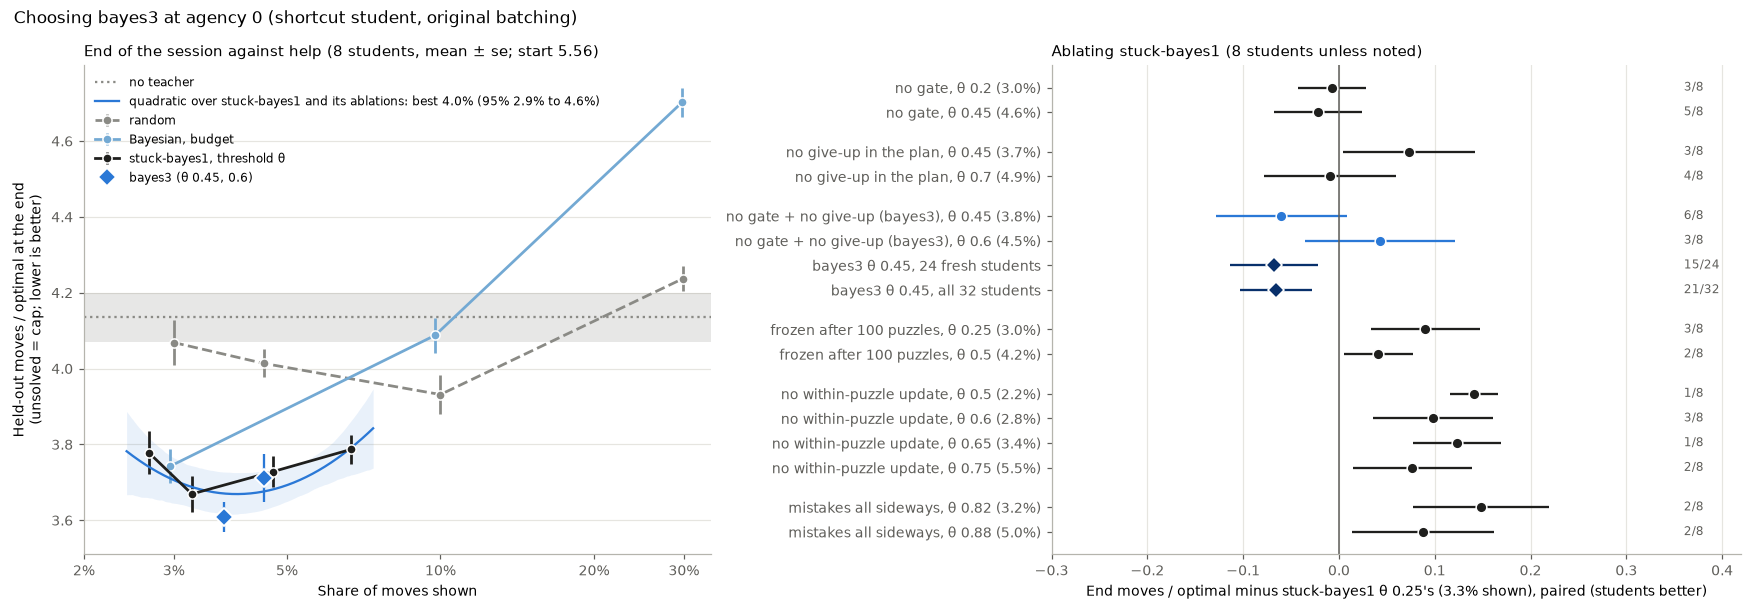

In [12]:
RUN0 = "teach_shortcut_agency0"
BASELINE = "stuck-bayes1:0.25"
BAYES3 = "stuck-bayes1:0.45,patience=0,giveup=0"
LINES = {"random": (["random:0.03", "random:0.045", "random:0.1", "random:0.3"], PEOPLE, "--"),
         "Bayesian, budget": (["bayes:0.03", "bayes:0.1", "bayes:0.3"], "#73a9d3", "-"),
         "stuck-bayes1, threshold θ": (["stuck-bayes1:0.1", "stuck-bayes1:0.25", "stuck-bayes1:0.5",
                                        "stuck-bayes1:0.75"], INK, "-")}
FIT_SPECS = ["stuck-bayes1:0.1", "stuck-bayes1:0.25", "stuck-bayes1:0.5", "stuck-bayes1:0.75",
             "stuck-bayes1:0.2,patience=0", "stuck-bayes1:0.45,patience=0", "stuck-bayes1:0.45,giveup=0",
             "stuck-bayes1:0.7,giveup=0", BAYES3, "stuck-bayes1:0.6,patience=0,giveup=0"]
ABLATIONS = {"no gate": ["stuck-bayes1:0.2,patience=0", "stuck-bayes1:0.45,patience=0"],
             "no give-up in the plan": ["stuck-bayes1:0.45,giveup=0", "stuck-bayes1:0.7,giveup=0"],
             "no gate + no give-up (bayes3)": [BAYES3, "stuck-bayes1:0.6,patience=0,giveup=0"],
             "frozen after 100 puzzles": ["stuck-bayes1:0.25,refit=100", "stuck-bayes1:0.5,refit=100"],
             "no within-puzzle update": ["stuck-bayes1:0.5,update=0", "stuck-bayes1:0.6,update=0",
                                         "stuck-bayes1:0.65,update=0", "stuck-bayes1:0.75,update=0"],
             "mistakes all sideways": ["stuck-bayes1:0.82,backward=0", "stuck-bayes1:0.88,backward=0"]}


def fit_curve(Y, x):
    R, S = Y.shape
    x0 = x.mean()
    A = np.zeros((R * S, S + 2))
    A[np.arange(R * S), np.tile(np.arange(S), R)] = 1
    A[:, S] = np.repeat(x - x0, S)
    A[:, S + 1] = np.repeat((x - x0) ** 2, S)
    beta = np.linalg.lstsq(A, Y.ravel(), rcond=None)[0]
    return beta[:S].mean(), beta[S], beta[S + 1], x0


fit_runs = [entry(RUN0, spec) for spec in FIT_SPECS]
students = sorted(ends(fit_runs[0]))
lx = np.array([np.log(spend(e)) for e in fit_runs])
Y = np.array([[ends(e)[s] for s in students] for e in fit_runs])
q0, q1, q2, x0 = fit_curve(Y, lx)
grid_x = np.linspace(lx.min() - 0.1, lx.max() + 0.1, 200)
rng = np.random.default_rng(0)
band, peaks = [], []
for _ in range(2000):
    idx = rng.integers(0, len(students), len(students))
    p0, p1, p2, _ = fit_curve(Y[:, idx], lx)
    band.append(p0 + p1 * (grid_x - x0) + p2 * (grid_x - x0) ** 2)
    peaks.append(x0 - p1 / (2 * p2) if p2 > 0 else np.nan)
lo, hi = np.percentile(band, [2.5, 97.5], axis=0)
plo, phi = np.exp(np.nanpercentile(peaks, [2.5, 97.5]))
peak = np.exp(x0 - q1 / (2 * q2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1, 1.1]})
a1.axhspan(nm - ns, nm + ns, color=PEOPLE, alpha=0.2, lw=0)
a1.axhline(nm, color=PEOPLE, lw=1.5, ls=":", label="no teacher")
for name, (specs_, color, ls) in LINES.items():
    pts = sorted((spend(e), *mean_se(ends(e).values())) for spec in specs_ for e in [entry(RUN0, spec)])
    xs, m, s = map(np.array, zip(*pts))
    a1.errorbar(xs, m, yerr=s, fmt=ls + "o", color=color, lw=1.8, ms=6, mec="white", label=name)
a1.fill_between(np.exp(grid_x), lo, hi, color=MODEL, alpha=0.1, lw=0)
a1.plot(np.exp(grid_x), q0 + q1 * (grid_x - x0) + q2 * (grid_x - x0) ** 2, color=MODEL, lw=1.5,
        label=f"quadratic over stuck-bayes1 and its ablations: best {peak:.1%} (95% {plo:.1%} to {phi:.1%})")
for spec in (BAYES3, "stuck-bayes1:0.6,patience=0,giveup=0"):
    e = entry(RUN0, spec)
    m, s = mean_se(ends(e).values())
    a1.errorbar(spend(e), m, yerr=s, fmt="D", color=MODEL, ms=8, mec="white", mew=1.2,
                label="bayes3 (θ 0.45, 0.6)" if spec == BAYES3 else None)
a1.set_xscale("log")
a1.set_xticks([0.02, 0.03, 0.05, 0.1, 0.2, 0.3], ["2%", "3%", "5%", "10%", "20%", "30%"])
a1.minorticks_off()
a1.set_xlabel("Share of moves shown")
a1.set_ylabel(END_LABEL)
a1.legend(loc="upper left", fontsize=8)
a1.set_title(f"End of the session against help (8 students, mean ± se; start {start_score(fit_runs[0]):.2f})")
tidy(a1)

b = ends(entry(RUN0, BASELINE))
yt, yl, y = [], [], 0
for label, specs_ in ABLATIONS.items():
    for spec in specs_:
        e = entry(RUN0, spec)
        d, s, better, n = diff(ends(e), b)
        a2.errorbar(d, y, xerr=s, fmt="o", color=MODEL if "bayes3" in label else INK, ms=7, mec="white")
        a2.text(0.36, y, f"{better}/{n}", va="center", fontsize=8, color=MUTED)
        yt.append(y)
        yl.append(f"{label}, θ {spec.split(':')[1].split(',')[0]} ({spend(e):.1%})")
        y -= 1
    if "bayes3" in label:
        fresh = ends(entry("teach_shortcut_agency0_confirm", BAYES3))
        fb = ends(entry("teach_shortcut_agency0_confirm", BASELINE))
        d24 = np.array([fresh[s_] - fb[s_] for s_ in fresh if s_ in fb])
        d8 = np.array([ends(entry(RUN0, BAYES3))[s_] - b[s_] for s_ in b])
        for name, d in (("bayes3 θ 0.45, 24 fresh students", d24), ("bayes3 θ 0.45, all 32 students",
                                                                    np.concatenate([d8, d24]))):
            m, s = mean_se(d)
            a2.errorbar(m, y, xerr=s, fmt="D", color="#08306b", ms=7, mec="white")
            a2.text(0.36, y, f"{(d < 0).sum()}/{len(d)}", va="center", fontsize=8, color=MUTED)
            yt.append(y)
            yl.append(name)
            y -= 1
    y -= 0.6
a2.axvline(0, color=MUTED, lw=1)
a2.set_yticks(yt, yl)
a2.set_xlim(-0.3, 0.42)
a2.set_xlabel(f"End moves / optimal minus stuck-bayes1 θ 0.25's ({spend(entry(RUN0, BASELINE)):.1%} shown), paired "
              "(students better)")
a2.set_title("Ablating stuck-bayes1 (8 students unless noted)")
tidy(a2, grid="x")
fig.suptitle("Choosing bayes3 at agency 0 (shortcut student, original batching)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

To verify that bayes3 is really the best model, along with the above ablations a parameter sweep of $\Delta A$ and $\theta$. This shows that the increased effectiveness of the bayesian model depends on $\Delta A$. In addition, it appears that regardless of what $\Delta A$ is chosen helping around 5-6% of the time is most effective (corresponding to a $\theta$ of 0.45).

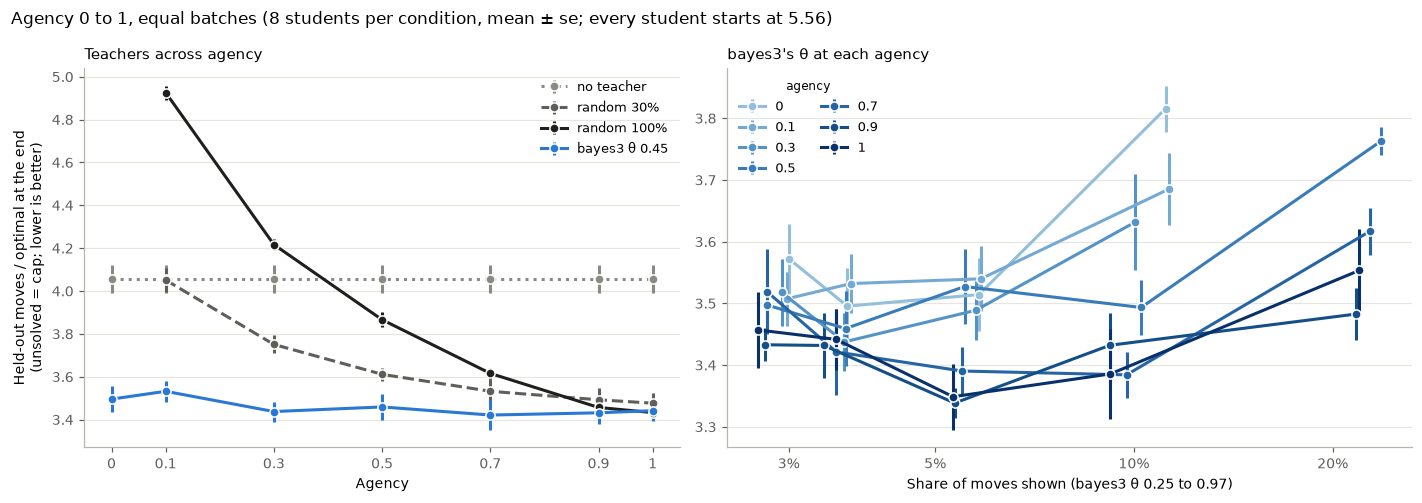

In [13]:
def run_of(a):
    return "teach_shortcut_agency1_even" if a == 1.0 else f"teach_shortcut_agency{a}_even"


def at(a, spec):
    return entry("teach_shortcut_agency0.0_even" if spec == "none" else run_of(a), spec)


THETAS = (0.25, 0.45, 0.75, 0.9, 0.97)
sweep = {(a, t): e for a in AGENCIES for t in THETAS for e in [at(a, f"bayes3:{t}")] if e is not None}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.15]})
for spec, name, color, ls in (("none", "no teacher", PEOPLE, ":"), ("random:0.3", "random 30%", MUTED, "--"),
                              ("random:1.0", "random 100%", INK, "-"), ("bayes3:0.45", "bayes3 θ 0.45", MODEL, "-")):
    pts = [(a, *mean_se(ends(e).values())) for a in AGENCIES for e in [at(a, spec)] if e is not None]
    xa, m, s = zip(*pts)
    axes[0].errorbar(xa, m, yerr=s, fmt=ls + "o", color=color, lw=2, ms=6, mec="white", label=name)
axes[0].set_xticks(AGENCIES, [f"{a:g}" for a in AGENCIES])
axes[0].set_xlabel("Agency")
axes[0].set_ylabel(END_LABEL)
axes[0].legend(loc="upper right")
axes[0].set_title("Teachers across agency")
tidy(axes[0])
for a in AGENCIES:
    pts = sorted((spend(e), *mean_se(ends(e).values())) for (aa, t), e in sweep.items() if aa == a)
    xs, m, s = map(np.array, zip(*pts))
    axes[1].errorbar(xs, m, yerr=s, fmt="-o", color=AGENCY_COLORS[a], lw=2, ms=6, mec="white", label=f"{a:g}")
axes[1].set_xscale("log")
axes[1].set_xticks([0.03, 0.05, 0.1, 0.2], ["3%", "5%", "10%", "20%"])
axes[1].minorticks_off()
axes[1].set_xlabel("Share of moves shown (bayes3 θ 0.25 to 0.97)")
axes[1].legend(loc="upper left", ncol=2, title="agency", title_fontsize=8)
axes[1].set_title("bayes3's θ at each agency")
tidy(axes[1])
fig.suptitle(f"Agency 0 to 1, equal batches (8 students per condition, mean ± se; every student starts at "
             f"{start_score(at(0.0, 'none')):.2f})", x=0.01, ha="left")
plt.tight_layout()
plt.show()